# SciPulse Insights — Notebook d'analyse (module 2)

**Auteur :** Toure Arouna · Mastère Data & IA (AIA01)

Ce notebook analyse la **couche Gold** produite par le pipeline Spark : l'index Elasticsearch
`arxiv-papers-enriched` (100 000 articles ArXiv enrichis des citations OpenAlex et du signal Hacker News).

Il répond à cinq questions :
1. Quelle part du corpus a pu être rapprochée des citations et de Hacker News ?
2. Comment se distribuent les citations et pourquoi une échelle logarithmique ?
3. Quels articles ont le plus d'impact selon le score composite, et que pèse chaque composante ?
4. L'écho Hacker News et l'impact académique vont-ils dans le même sens ?
5. Le classement est-il robuste aux pondérations du score (analyse de sensibilité) ?

**Prérequis** : le stack Docker démarré (Elasticsearch sur `localhost:9200`) et, dans le venv :
`pip install jupyter matplotlib pandas "elasticsearch>=8,<9"`

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from elasticsearch import Elasticsearch, helpers

ES_URL = os.getenv("ES_URL", "http://localhost:9200")
INDEX = "arxiv-papers-enriched"
CACHE = Path("../reports/gold_snapshot.pkl")   # reports/ est ignoré par Git

VERT_FONCE, VERT, VERT_CLAIR, GRIS = "#0F3D2E", "#1F8A5B", "#5FD49A", "#8FA39A"
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_colwidth", 70)

## 1. Chargement de la couche Gold

On lit l'index Elasticsearch avec un *scroll* (`helpers.scan`), en ne demandant que les champs utiles.
Le résultat est mis en cache localement pour ne pas relire l'index à chaque exécution.

In [2]:
CHAMPS = ["arxiv_id", "title", "primary_category", "published_year", "match_method", "subfield_name",
          "cited_by_count", "citations_3ans", "has_hn", "hn_score", "hn_comments", "is_withdrawn",
          "score_citations", "score_velocite", "score_hn", "score_recence", "score_impact"]

def charger_gold(force: bool = False) -> pd.DataFrame:
    if CACHE.exists() and not force:
        return pd.read_pickle(CACHE)
    es = Elasticsearch(ES_URL, request_timeout=120)
    docs = (h["_source"] for h in helpers.scan(es, index=INDEX, query={"query": {"match_all": {}}},
                                               _source=CHAMPS, size=5000))
    df = pd.DataFrame(docs, columns=CHAMPS)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    df.to_pickle(CACHE)
    return df

gold = charger_gold()
NUMERIQUES = ["cited_by_count", "citations_3ans", "hn_score", "hn_comments", "published_year",
              "score_citations", "score_velocite", "score_hn", "score_recence", "score_impact"]
for col in NUMERIQUES:
    gold[col] = pd.to_numeric(gold[col], errors="coerce").fillna(0)
gold["has_hn"] = gold["has_hn"].fillna(False).astype(bool)
gold["is_withdrawn"] = gold["is_withdrawn"].fillna(False).astype(bool)
print(f"{len(gold):,} articles chargés · {gold['arxiv_id'].nunique():,} identifiants distincts")
gold.head(3)

100,000 articles chargés · 100,000 identifiants distincts


,arxiv_id,title,primary_category,published_year,match_method,subfield_name,cited_by_count,citations_3ans,has_hn,hn_score,hn_comments,is_withdrawn,score_citations,score_velocite,score_hn,score_recence,score_impact
0,0708.1157,Stability and instability of nonlinear defect states in the couple...,nlin.PS,2007,arxiv_id,Statistical and Nonlinear Physics,15,0.000000,False,0.0,0.0,False,0.248659,0.000000,0.0,0.011840,10.124
1,0708.1203,Exciton Effects in Optical Absorption of Boron-Nitride Nanotubes,cond-mat.mtrl-sci,2007,arxiv_id,Materials Chemistry,0,0.000000,False,0.0,0.0,False,0.000000,0.000000,0.0,0.011848,0.178
2,0708.1394,Semiclassical description of the kinematically complete experiments,physics.atom-ph,2007,arxiv_id,"Atomic and Molecular Physics, and Optics",21,0.666667,False,0.0,0.0,False,0.277219,0.056572,0.0,0.011855,12.681


## 2. Couverture des sources

La qualité de la jointure conditionne tout le reste : un article non rapproché d'OpenAlex n'a pas de citations,
donc un score quasi nul.

,articles,part (%)
méthode,,
arxiv_id,98186,98.19
none,1499,1.50
title_fallback,171,0.17
doi,144,0.14


Appariés à OpenAlex : 98,501 (98.5 %)
Discutés sur Hacker News : 518 (0.52 %)


C:\Users\DELL PC\Downloads\Projet SciPulse\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10781 (\N{JOIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


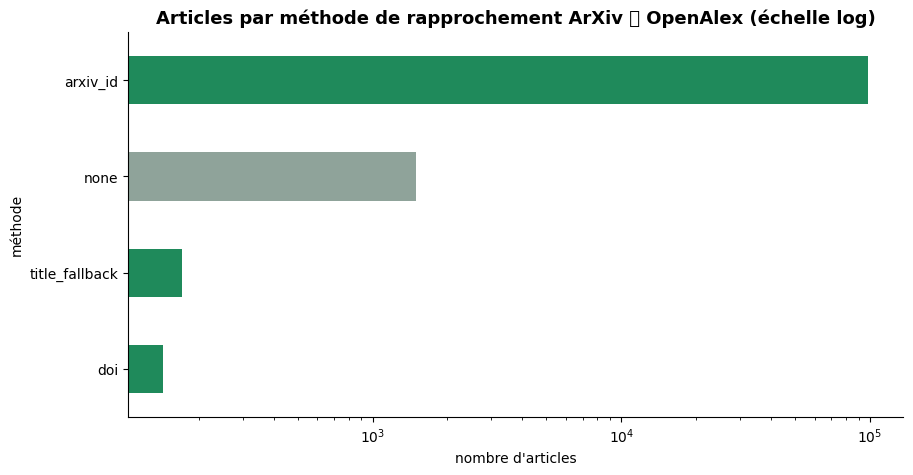

In [3]:
couverture = (gold["match_method"].fillna("none").value_counts()
              .rename_axis("méthode").to_frame("articles"))
couverture["part (%)"] = (100 * couverture["articles"] / len(gold)).round(2)
display(couverture)

apparies = (gold["match_method"].fillna("none") != "none").sum()
print(f"Appariés à OpenAlex : {apparies:,} ({100 * apparies / len(gold):.1f} %)")
print(f"Discutés sur Hacker News : {gold['has_hn'].sum():,} ({100 * gold['has_hn'].mean():.2f} %)")

ax = couverture["articles"].plot.barh(color=[VERT if m != "none" else GRIS for m in couverture.index])
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_title("Articles par méthode de rapprochement ArXiv ⨝ OpenAlex (échelle log)")
ax.set_xlabel("nombre d'articles"); plt.show()

**Lecture.** Le rapprochement par identifiant ArXiv couvre la quasi-totalité du corpus. Le DOI éditeur n'apporte
qu'une poignée d'articles : beaucoup de préprints ArXiv n'ont jamais été publiés en revue (question de synthèse J2).

## 3. Distribution des citations : pourquoi le logarithme

Les citations suivent une loi à queue lourde : quelques articles concentrent une part énorme des citations.

count    98501.0
mean        39.3
std        345.3
min          0.0
50%          7.0
90%         78.0
99%        440.0
max      69575.0

Le 1 % d'articles les plus cités concentre 33.1 % des citations.


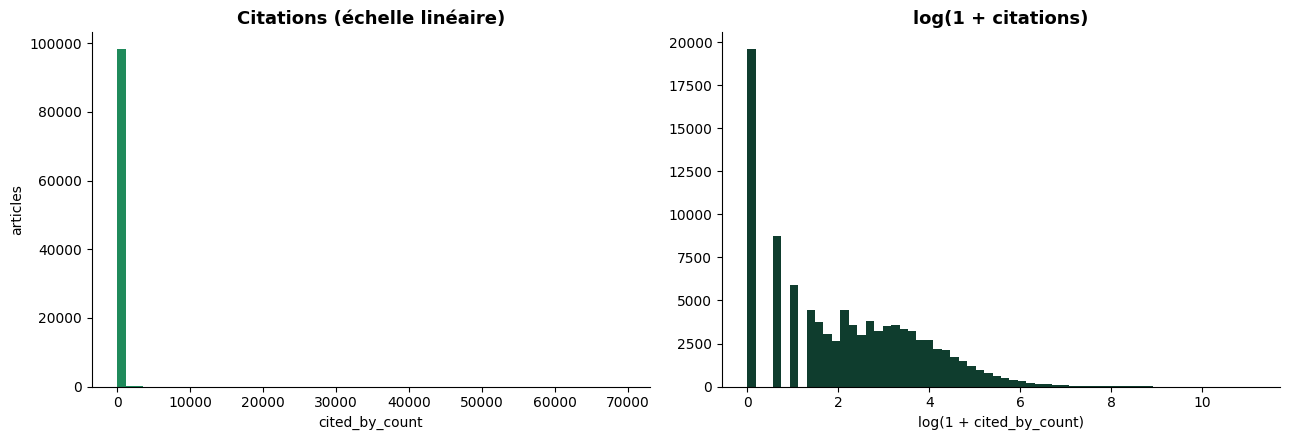

In [4]:
cit = gold.loc[gold["match_method"].fillna("none") != "none", "cited_by_count"]
print(cit.describe(percentiles=[.5, .9, .99]).round(1).to_string())
top1 = cit.sort_values(ascending=False).head(int(len(cit) * 0.01)).sum() / cit.sum()
print(f"\nLe 1 % d'articles les plus cités concentre {100 * top1:.1f} % des citations.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(cit, bins=60, color=VERT); axes[0].set_title("Citations (échelle linéaire)")
axes[0].set_xlabel("cited_by_count"); axes[0].set_ylabel("articles")
axes[1].hist(np.log1p(cit), bins=60, color=VERT_FONCE); axes[1].set_title("log(1 + citations)")
axes[1].set_xlabel("log(1 + cited_by_count)")
plt.tight_layout(); plt.show()

**Lecture.** En échelle linéaire, presque tout le corpus est écrasé contre zéro. Après `log(1 + x)`, la distribution
devient exploitable : c'est pourquoi chaque composante du score est passée en logarithme puis normalisée par son maximum.

## 4. Score d'impact composite

`score_impact = 100 × (0,40 · citations + 0,25 · vélocité + 0,20 · HN + 0,15 · récence)`

,title,primary_category,cited_by_count,hn_score,score_impact
0,Scikit-learn: Machine Learning in Python,cs.LG,69575,0.0,65.49
1,Efficient Estimation of Word Representations in Vector Space,cs.CL,26002,3.0,62.55
2,SMOTE: Synthetic Minority Over-sampling Technique,cs.AI,32505,0.0,60.80
3,Rich feature hierarchies for accurate object detection and semanti...,cs.CV,32625,0.0,60.77
4,Distributed Representations of Words and Phrases and their Composi...,cs.CL,24512,0.0,57.08
5,Fast unfolding of communities in large networks,physics.soc-ph,21231,0.0,56.96
6,Canonical sampling through velocity-rescaling,cond-mat.stat-mech,18120,0.0,56.47
7,emcee: The MCMC Hammer,astro-ph.IM,13365,0.0,55.01
8,Community detection in graphs,physics.soc-ph,11270,2.0,54.96
9,The NumPy array: a structure for efficient numerical computation,cs.MS,10590,1.0,54.59


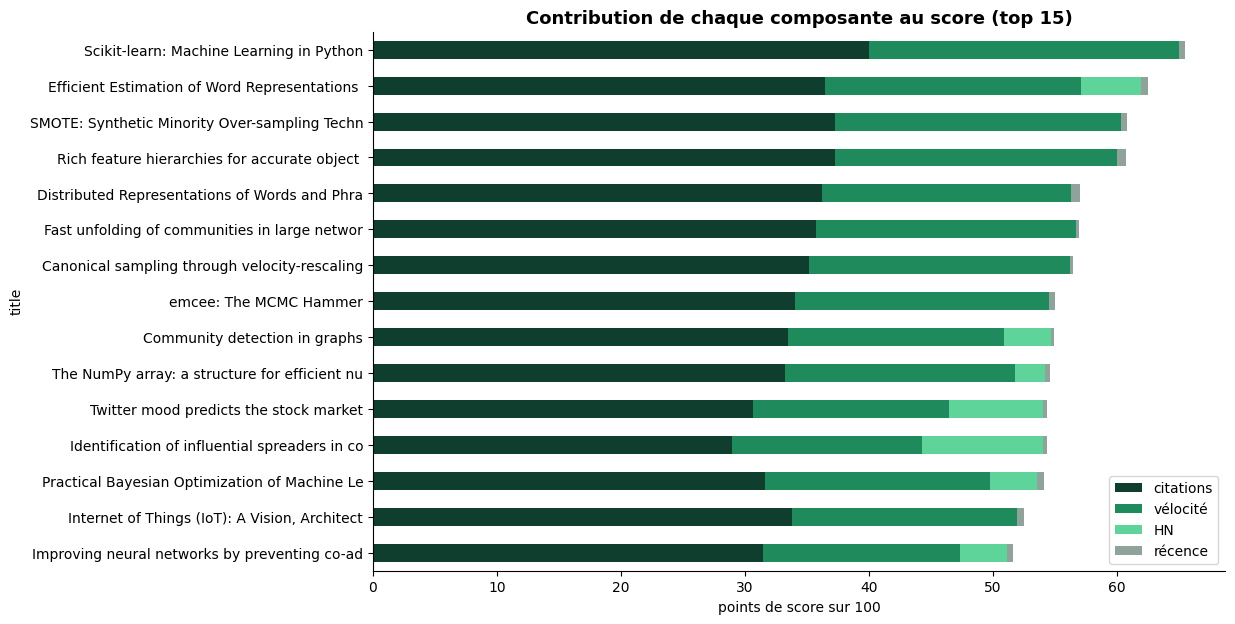

In [5]:
POIDS = {"score_citations": 0.40, "score_velocite": 0.25, "score_hn": 0.20, "score_recence": 0.15}
actifs = gold[~gold["is_withdrawn"]]

top = actifs.nlargest(15, "score_impact")[["title", "primary_category", "cited_by_count", "hn_score", "score_impact"]]
display(top.reset_index(drop=True).round(2))

contrib = pd.DataFrame({c: 100 * w * actifs.nlargest(15, "score_impact")[c] for c, w in POIDS.items()})
contrib.index = actifs.nlargest(15, "score_impact")["title"].str.slice(0, 45)
ax = contrib[::-1].plot.barh(stacked=True, figsize=(11, 7),
                             color=[VERT_FONCE, VERT, VERT_CLAIR, GRIS])
ax.set_title("Contribution de chaque composante au score (top 15)")
ax.set_xlabel("points de score sur 100"); ax.legend(["citations", "vélocité", "HN", "récence"], loc="lower right")
plt.show()

count    99850.00
mean         9.33
std          7.72
min          0.16
50%          8.11
90%         19.99
99%         31.20
max         65.49


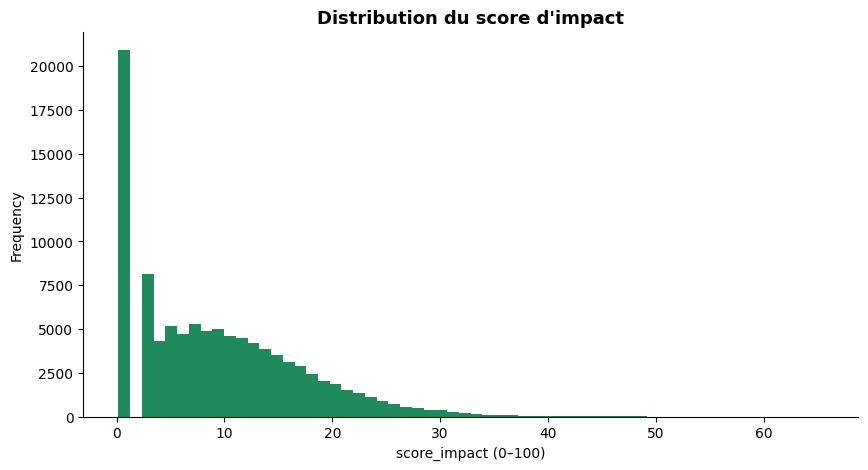

In [6]:
print(actifs["score_impact"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
ax = actifs["score_impact"].plot.hist(bins=60, color=VERT)
ax.set_title("Distribution du score d'impact"); ax.set_xlabel("score_impact (0–100)"); plt.show()

## 5. Écho Hacker News contre impact académique

517 articles discutés sur HN · corrélation de rang (Spearman) points HN / citations : -0.02


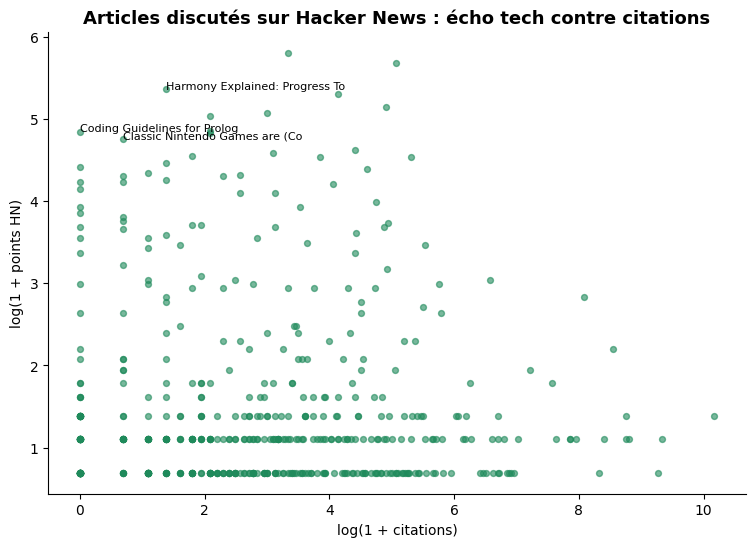

Viraux sur HN mais peu cités :


,title,hn_score,cited_by_count
25715,Coding Guidelines for Prolog,126.0,0
53342,Harmony Explained: Progress Towards A Scientific Theory of Music,213.0,3
53683,Classic Nintendo Games are (Computationally) Hard,115.0,1


Très cités mais absents de HN :


,title,cited_by_count
0,Scikit-learn: Machine Learning in Python,69575
1,Rich feature hierarchies for accurate object detection and semanti...,32625
2,SMOTE: Synthetic Minority Over-sampling Technique,32505
3,Distributed Representations of Words and Phrases and their Composi...,24512
4,Fast unfolding of communities in large networks,21231
5,Canonical sampling through velocity-rescaling,18120
6,emcee: The MCMC Hammer,13365
7,"Internet of Things (IoT): A Vision, Architectural Elements, and Fu...",12259
8,A Tutorial on Spectral Clustering,10351
9,Power-law distributions in empirical data,7986


In [7]:
hn = actifs[actifs["has_hn"]]
corr = hn[["hn_score", "cited_by_count"]].corr(method="spearman").iloc[0, 1]
print(f"{len(hn)} articles discutés sur HN · corrélation de rang (Spearman) points HN / citations : {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(np.log1p(hn["cited_by_count"]), np.log1p(hn["hn_score"]), s=18, alpha=0.6, color=VERT)
ax.set_xlabel("log(1 + citations)"); ax.set_ylabel("log(1 + points HN)")
ax.set_title("Articles discutés sur Hacker News : écho tech contre citations")
for _, r in hn[(hn["hn_score"] > 100) & (hn["cited_by_count"] < 5)].iterrows():
    ax.annotate(r["title"][:30], (np.log1p(r["cited_by_count"]), np.log1p(r["hn_score"])), fontsize=8)
plt.show()

print("Viraux sur HN mais peu cités :")
display(hn[(hn["hn_score"] > 100) & (hn["cited_by_count"] < 5)][["title", "hn_score", "cited_by_count"]])
print("Très cités mais absents de HN :")
display(actifs[(actifs["cited_by_count"] > 50) & ~actifs["has_hn"]]
        .nlargest(10, "cited_by_count")[["title", "cited_by_count"]].reset_index(drop=True))

**Lecture.** Les deux signaux ne mesurent pas la même chose : certains articles très populaires sur HN ne sont
presque pas cités, et des références majeures (Scikit-learn, R-CNN, SMOTE) n'ont jamais été discutées sur HN dans
notre corpus. Le score composite combine donc deux formes d'impact réellement distinctes.

## 6. Score par année et par méthode de rapprochement

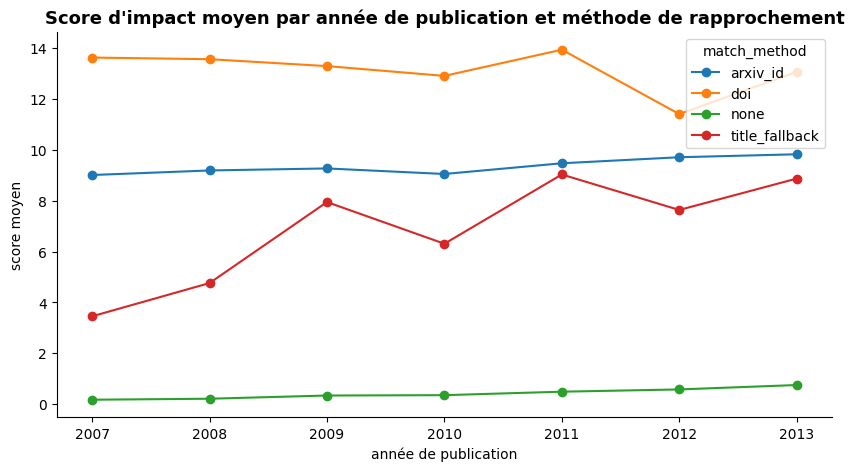

match_method,arxiv_id,doi,none,title_fallback
published_year,,,,
2007,9.00,13.62,0.18,3.46
2008,9.18,13.55,0.22,4.76
2009,9.26,13.28,0.34,7.94
2010,9.04,12.90,0.36,6.30
2011,9.46,13.92,0.50,9.02
2012,9.70,11.40,0.58,7.63
2013,9.82,13.05,0.76,8.86


In [8]:
pivot = (actifs.assign(match_method=actifs["match_method"].fillna("none"))
         .groupby(["published_year", "match_method"])["score_impact"].mean().unstack())
ax = pivot.plot(marker="o", figsize=(10, 5))
ax.set_title("Score d'impact moyen par année de publication et méthode de rapprochement")
ax.set_xlabel("année de publication"); ax.set_ylabel("score moyen"); plt.show()
display(pivot.round(2))

**Lecture.** Les articles appariés par DOI (souvent publiés en revue) ont le score le plus élevé ; les articles non
appariés restent proches de 0 faute de citations. Le corpus couvrant 2007–2013, les âges sont proches et la
composante de récence départage peu.

## 7. Analyse de sensibilité des pondérations

On recalcule le classement avec d'autres jeux de poids à partir des quatre composantes normalisées, et on mesure
le recouvrement du top 100 avec la configuration par défaut.

,configuration,recouvrement top 100 (%),n° 1
0,par_defaut,100,Scikit-learn: Machine Learning in Python
1,sans_recence,96,Scikit-learn: Machine Learning in Python
2,citations_seules,85,Scikit-learn: Machine Learning in Python
3,hn_dominant,19,"There are no particles, there are only fields"


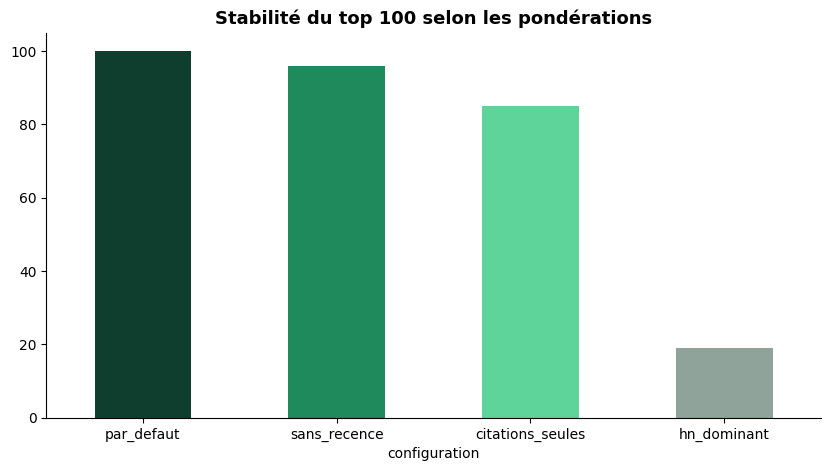

In [9]:
CONFIGS = {
    "par_defaut":       {"score_citations": 0.40, "score_velocite": 0.25, "score_hn": 0.20, "score_recence": 0.15},
    "sans_recence":     {"score_citations": 0.50, "score_velocite": 0.30, "score_hn": 0.20, "score_recence": 0.00},
    "citations_seules": {"score_citations": 1.00, "score_velocite": 0.00, "score_hn": 0.00, "score_recence": 0.00},
    "hn_dominant":      {"score_citations": 0.20, "score_velocite": 0.10, "score_hn": 0.60, "score_recence": 0.10},
}
comp = actifs[["arxiv_id", "title", *POIDS]].fillna(0)

def top_ids(poids, n=100):
    s = sum(comp[c] * w for c, w in poids.items())
    return comp.assign(_s=s).nlargest(n, "_s")

ref = set(top_ids(CONFIGS["par_defaut"])["arxiv_id"])
lignes = []
for nom, poids in CONFIGS.items():
    t = top_ids(poids)
    lignes.append({"configuration": nom, "recouvrement top 100 (%)": len(set(t["arxiv_id"]) & ref),
                   "n° 1": t.iloc[0]["title"][:60]})
sens = pd.DataFrame(lignes)
display(sens)

ax = sens.set_index("configuration")["recouvrement top 100 (%)"].plot.bar(
    color=[VERT_FONCE, VERT, VERT_CLAIR, GRIS], rot=0)
ax.set_title("Stabilité du top 100 selon les pondérations"); ax.set_ylim(0, 105); plt.show()

**Lecture.** Le classement est stable pour des variations raisonnables des poids et ne bascule que si Hacker News
devient majoritaire. À 20 %, HN apporte un signal sans dominer (question de synthèse J3). Pour calibrer objectivement
les poids, il faudrait une vérité terrain, par exemple prédire les citations à N+2.

## 8. Benchmark Pandas contre Spark (question J1)

Mesuré par `src/spark_jobs/benchmark_pandas_vs_spark.py` (comptage des articles par catégorie) :

In [10]:
bench = pd.DataFrame([
    {"outil": "Pandas", "articles": 100_000,   "temps (s)": 9.13},
    {"outil": "Spark",  "articles": 100_000,   "temps (s)": 46.10},
    {"outil": "Spark",  "articles": 3_002_164, "temps (s)": 180.25},
])
bench["µs / article"] = (1e6 * bench["temps (s)"] / bench["articles"]).round(1)
display(bench)

,outil,articles,temps (s),µs / article
0,Pandas,100000,9.13,91.3
1,Spark,100000,46.10,461.0
2,Spark,3002164,180.25,60.0


**Lecture.** Sur 100 000 articles, Pandas est 5 fois plus rapide : Spark paie un coût fixe (planification, inférence
du schéma). Sur le fichier complet de 5,2 Go, le volume est multiplié par 30 mais le temps Spark seulement par 3,9,
et le coût par article passe sous celui de Pandas, qui ne pourrait de toute façon pas charger le fichier en mémoire.
Le point de bascule est atteint quand les données ne tiennent plus en mémoire d'une seule machine.

## 9. Conclusions

- **98,5 %** des articles sont rapprochés de leurs citations grâce à une ingestion ciblée par identifiant ArXiv.
- Les citations ont une distribution à queue lourde : l'échelle logarithmique est indispensable au score.
- Écho Hacker News et citations mesurent deux formes d'impact différentes, d'où l'intérêt d'un score composite.
- Le classement est robuste aux pondérations raisonnables.
- **Limites** : corpus 2007–2013 (récence et HN peu discriminants), pondérations non calibrées sur une vérité terrain.